<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/_banners/opim5512_banner.svg" alt="OPIM 5512 banner" width="100%">

# Lab 5 · Building the training data: Bradley weather + Connecticut electricity load, 2023 to now

**OPIM 5512 · Module 4 · Dr. Dave**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drdave-teaching/OPIM5512-notebooks/blob/main/Module4/Lab5_Building_the_Training_Data.ipynb)

Before you forecast anything, you need a clean history. This notebook builds the one we use all of Module 4 and the
final project: **every hour from Jan 1, 2023 to Oct 15, 2026**, with the weather at **Bradley Airport (BDL)** and the
electricity load of the **Connecticut zone** of the New England grid.

**The official copy is always on GitHub:**
[`Module4/data/bdl_ct_load_hourly_2023_2026.csv`](https://github.com/drdave-teaching/OPIM5512-notebooks/blob/main/Module4/data/bdl_ct_load_hourly_2023_2026.csv).
That's the file Lab 5, Lab 6 and the final project read. This notebook rebuilds it from the raw downloads, and Part 7
checks that your copy matches it number for number. You don't have to run this notebook to do Lab 5; it shows you
where every number came from, and it's the recipe to follow if you add more weather stations.

The golden rule: **one row per hour, no gaps, no duplicates.** Jan 1, 2023 to Oct 15, 2026 is 1,384 days (2024 is a
leap year) × 24 = 33,216 hours, **minus 1**: the period has four spring-forward days (23 hours) but only three fall-back
days (25 hours), because Nov 1, 2026 comes after Oct 15. So the final table must have exactly **33,215 rows**. We check
that in Part 7.

**The two sources**
| Data | Where it comes from | What it measures |
|---|---|---|
| Weather | Iowa State Mesonet archive of the official airport reports (METARs) at Bradley | Temperature, humidity, wind, clouds, rain, ... |
| Load | ISO New England web services, *real-time hourly demand*, Connecticut zone (location 4004) | Average megawatts (MW) used in Connecticut in that hour |

**The time trap: daylight saving.** Twice a year, local clock time breaks: in March one hour never happens, in November
one hour happens twice. If you join on local time you silently lose or double rows. So we store every time in **UTC**,
which never jumps, and add local time only at the very end for convenience. Part 6 shows the trap before and after.

| Part | What you do |
|---|---|
| 1 | Look at the raw airport reports: how often they come, and which columns are really missing |
| 2–3 | One report per hour on a complete grid of hours, so the gaps show up |
| 4 | Tidy the units so history matches the live forecast |
| 5 | Fill the gaps one variable at a time, and **test** which filling method works best |
| 6 | The Connecticut load, and the daylight-saving trap before and after |
| 7 | Join, check, save, and compare with the official file |
| 8 | First look: why weather predicts electricity |
| 9 | Preview: the window method (lags) |

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/"
YEARS = [2022, 2023, 2024, 2025, 2026]   # the last days of 2022 are padding for filling gaps at the start

## 1. The raw weather: what an airport report looks like
Bradley sends a **routine report at 51 minutes past every hour**, plus extra **special reports** whenever the weather
changes quickly (a storm rolls in, visibility drops). We downloaded every report from the Iowa State Mesonet, in UTC,
one file per year. (Want the live version? The download link is in the comments below. Please don't hammer it: the
Mesonet is a free service run by Iowa State University.)

In [2]:
# Download link (one year shown): https://mesonet.agron.iastate.edu/cgi-bin/request/asos.py?station=BDL
#   &data=tmpf&data=dwpf&data=relh&data=drct&data=sknt&data=gust&data=p01i&data=alti&data=mslp&data=vsby
#   &data=skyc1&data=skyc2&data=skyc3&data=skyc4&data=wxcodes&data=feel&year1=2023&month1=1&day1=1&year2=2024&month2=1&day2=1
#   &tz=Etc%2FUTC&format=onlycomma&report_type=3&report_type=4      (3 = routine, 4 = special)
pieces = []
for year in YEARS:
    one_year = pd.read_csv(DATA + "raw/BDL_asos_" + str(year) + ".csv", na_values=["M"], keep_default_na=False)
    pieces.append(one_year)
raw = pd.concat(pieces, ignore_index=True)
raw["valid"] = pd.to_datetime(raw["valid"], utc=True)     # the report time, already in UTC
print(len(raw), "reports")
raw.head()

40876 reports


,station,valid,tmpf,dwpf,relh,drct,sknt,gust,p01i,alti,vsby,skyc1,skyc2,skyc3,skyc4,wxcodes,feel
0,BDL,2022-12-25 00:51:00+00:00,12.9,-4.0,46.02,240.0,17.0,20.0,0.00,29.76,10.0,CLR,NaN,NaN,NaN,NaN,-4.95
1,BDL,2022-12-25 01:51:00+00:00,12.0,-3.0,50.47,240.0,11.0,NaN,0.00,29.78,10.0,CLR,NaN,NaN,NaN,NaN,-2.81
2,BDL,2022-12-25 02:51:00+00:00,12.9,-4.0,46.02,240.0,13.0,23.0,0.00,29.78,10.0,CLR,NaN,NaN,NaN,NaN,-2.90
3,BDL,2022-12-25 03:51:00+00:00,12.9,-3.0,48.50,250.0,16.0,NaN,0.00,29.78,10.0,SCT,NaN,NaN,NaN,NaN,-4.48
4,BDL,2022-12-25 04:51:00+00:00,12.9,-3.0,48.50,230.0,16.0,21.0,0.00,29.78,10.0,BKN,NaN,NaN,NaN,NaN,-4.48


**What the columns mean** (US airport units): `tmpf` temperature (°F), `dwpf` dew point (°F), `relh` relative humidity
(%), `drct` wind direction (degrees), `sknt` wind speed (knots), `gust` gust (knots), `p01i` rain in the last hour
(inches), `alti` pressure (inches of mercury), `vsby` visibility (miles), `skyc1` to `skyc4` up to four cloud layers (CLR,
FEW, SCT, BKN, OVC), `wxcodes` weather codes (RA = rain, SN = snow, BR = mist, FG = fog), `feel` "feels like" (°F).

### Look at the mess before you clean it

In [3]:
minutes = raw["valid"].dt.minute
print("Reports at :51 (routine):", (minutes == 51).sum())
print("Other minutes (specials):", (minutes != 51).sum())
print()
print("Missing gust:", raw["gust"].isna().mean().round(3) * 100, "% of reports (no gust was reported)")
print("Trace rain 'T':", (raw["p01i"] == "T").sum(), "reports (too little to measure)")
print("Lowest-layer sky codes:", raw["skyc1"].value_counts().to_dict())
print("Reports with a 2nd cloud layer:", raw["skyc2"].notna().sum())

Reports at :51 (routine): 33458
Other minutes (specials): 7418

Missing gust: 87.7 % of reports (no gust was reported)
Trace rain 'T': 3662 reports (too little to measure)
Lowest-layer sky codes: {'FEW': 17753, 'BKN': 8901, 'SCT': 6290, 'OVC': 4524, 'CLR': 2895, 'VV ': 512}
Reports with a 2nd cloud layer: 25610


### 1b. How often does Bradley report?
A calm day has **24 reports**, one routine report per hour. When the weather changes fast (a thunderstorm, snow,
fog rolling in), the airport sends extra **special reports**, sometimes dozens in a day. A day with **fewer than 24**
means some reports never arrived. Copy this cell and change the plot to dig in.

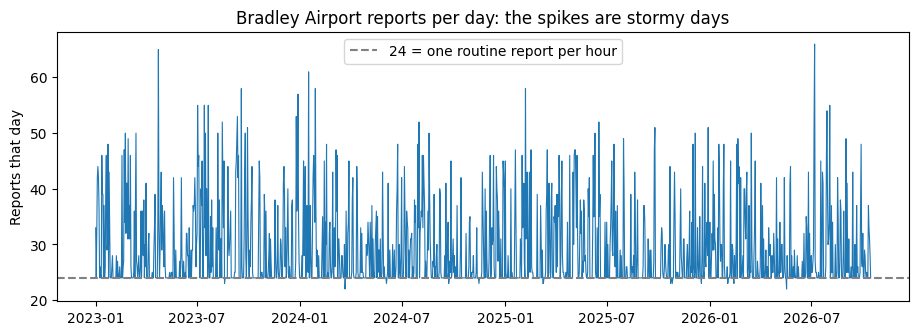

Days with fewer than 24 reports: 13 of 1384
The five busiest days:


valid
2026-07-07 00:00:00-04:00    66
2023-04-23 00:00:00-04:00    65
2024-01-16 00:00:00-05:00    61
2025-02-06 00:00:00-05:00    58
2023-09-18 00:00:00-04:00    58
dtype: int64

In [4]:
# Reports per calendar day (Connecticut time). 24 = one routine report per hour.
per_day = raw.set_index("valid").tz_convert("America/New_York").resample("D").size()
per_day = per_day.loc["2023-01-01":"2026-10-15"]

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(per_day.index, per_day.values, linewidth=0.8)
ax.axhline(24, color="gray", linestyle="--", label="24 = one routine report per hour")
ax.set_ylabel("Reports that day")
ax.set_title("Bradley Airport reports per day: the spikes are stormy days")
ax.legend()
plt.show()

print("Days with fewer than 24 reports:", int((per_day < 24).sum()), "of", len(per_day))
print("The five busiest days:")
per_day.sort_values(ascending=False).head(5)

**Zoom in on the busiest day.** Each dot is one report. Routine reports (at :51) come once an hour; the special ones
pile up exactly when visibility drops. That's the weather the specials were written for.

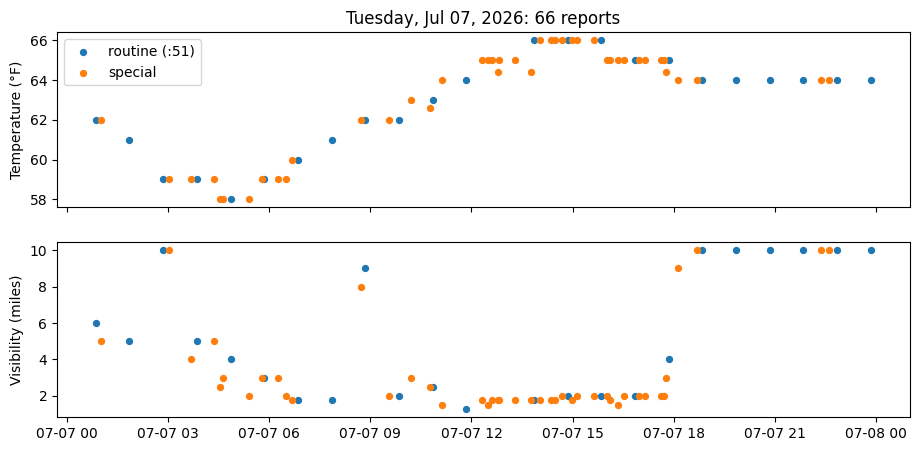

Weather codes that day: {'-RA BR': 33, 'RA BR': 16, '+RA BR': 3}


In [5]:
busiest = per_day.idxmax()
local_valid = raw["valid"].dt.tz_convert("America/New_York")
day = raw[local_valid.dt.normalize() == busiest].copy()
day["local_time"] = day["valid"].dt.tz_convert("America/New_York")
routine = day[day["valid"].dt.minute == 51]
special = day[day["valid"].dt.minute != 51]

fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax[0].scatter(routine["local_time"], routine["tmpf"], s=18, label="routine (:51)")
ax[0].scatter(special["local_time"], special["tmpf"], s=18, color="tab:orange", label="special")
ax[0].set_ylabel("Temperature (°F)")
ax[0].legend()
ax[1].scatter(routine["local_time"], routine["vsby"], s=18)
ax[1].scatter(special["local_time"], special["vsby"], s=18, color="tab:orange")
ax[1].set_ylabel("Visibility (miles)")
ax[0].set_title(busiest.strftime("%A, %b %d, %Y") + ": " + str(len(day)) + " reports")
plt.show()

print("Weather codes that day:", day["wxcodes"].value_counts().head(6).to_dict())

### 1c. Data completeness, column by column
Two very different things show up as "missing" in airport data:
- **A real gap:** the sensor sent nothing. These we fill in Part 5.
- **Nothing to report:** no gust, no second cloud layer, no rain or fog. The blank **is** the information, so we
  don't fill it like a gap; Part 4 turns it into a value (gust = the wind speed, no weather code = 0).

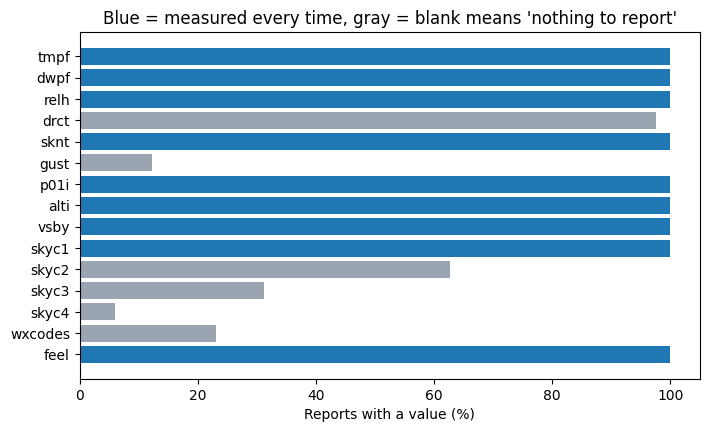

,present_pct,a blank means
tmpf,100.0,a real gap (the sensor sent nothing)
dwpf,100.0,a real gap (the sensor sent nothing)
relh,100.0,a real gap (the sensor sent nothing)
drct,97.6,wind too light or shifting to give a direction...
sknt,100.0,a real gap (the sensor sent nothing)
gust,12.3,no gust: the wind was steady
p01i,100.0,a real gap (the sensor sent nothing)
alti,100.0,a real gap (the sensor sent nothing)
vsby,100.0,a real gap (the sensor sent nothing)
skyc1,100.0,a real gap (the sensor sent nothing)


In [6]:
# How complete is each raw column? And what does a blank mean in that column?
NOTHING_TO_REPORT = {"gust": "no gust: the wind was steady",
                     "skyc2": "only one cloud layer", "skyc3": "two layers or fewer", "skyc4": "three layers or fewer",
                     "wxcodes": "no rain, snow or fog happening",
                     "drct": "wind too light or shifting to give a direction (VRB)"}

completeness = pd.DataFrame({"present_pct": (100 * raw.notna().mean()).round(1)})
completeness = completeness.drop(["station", "valid"])
completeness["a blank means"] = "a real gap (the sensor sent nothing)"
for column in NOTHING_TO_REPORT:
    completeness.loc[column, "a blank means"] = NOTHING_TO_REPORT[column]

colors = []
for column in completeness.index:
    if column in NOTHING_TO_REPORT:
        colors.append("#9aa5b1")
    else:
        colors.append("#1f77b4")
plt.figure(figsize=(8, 4.5))
plt.barh(completeness.index, completeness["present_pct"], color=colors)
plt.gca().invert_yaxis()
plt.xlabel("Reports with a value (%)")
plt.title("Blue = measured every time, gray = blank means 'nothing to report'")
plt.show()
completeness

**Does completeness change over time?** A sensor that breaks for a month shows up as a dark stripe. Each column is a
month, each row a raw column, and the color is the share of reports with a value.

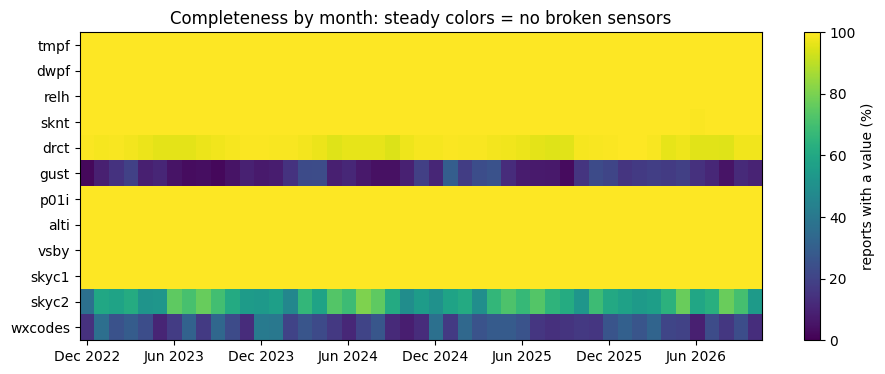

In [7]:
TO_MAP = ["tmpf", "dwpf", "relh", "sknt", "drct", "gust", "p01i", "alti", "vsby", "skyc1", "skyc2", "wxcodes"]
monthly = raw.set_index("valid")[TO_MAP].notna().resample("MS").mean() * 100

fig, ax = plt.subplots(figsize=(11, 4))
image = ax.imshow(monthly.T.values, aspect="auto", cmap="viridis", vmin=0, vmax=100)
ax.set_yticks(range(len(TO_MAP)))
ax.set_yticklabels(TO_MAP)
positions = list(range(0, len(monthly), 6))
labels = []
for position in positions:
    labels.append(monthly.index[position].strftime("%b %Y"))
ax.set_xticks(positions)
ax.set_xticklabels(labels)
fig.colorbar(image, label="reports with a value (%)")
ax.set_title("Completeness by month: steady colors = no broken sensors")
plt.show()

Four things to fix:
1. **Several reports in some hours** (specials), and a few hours with **none at all**.
2. **"T" for trace rain** is text in a number column.
3. **A missing gust** isn't missing data: it means no gust was reported.
4. **Sky cover is a code**, not a number, spread over up to **four layers** (a few low clouds can sit under a thick
   deck), and "VV" means the sky is hidden (fog), which counts as fully covered.

## 2. One report per hour, lined up with the load
ISO-NE labels each hour by when it **begins**: the 11:00 row is the load from 11:00 to 12:00. The 10:51 report
describes the weather right at the start of that hour, so we round each report to the **nearest hour** (10:51 → 11:00).
When an hour has more than one report, we keep the **routine** one; if there's no routine report, the one closest to the
hour.

In [8]:
raw["hour_utc"] = raw["valid"].dt.round("h")                      # 10:51 -> 11:00
raw["minutes_off"] = (raw["valid"] - raw["hour_utc"]).abs().dt.total_seconds() / 60
raw["is_routine"] = raw["valid"].dt.minute == 51

# Sort so that, within each hour, the routine report comes first, then the closest one; keep the first
raw = raw.sort_values(["hour_utc", "is_routine", "minutes_off"], ascending=[True, False, True])
hourly = raw.drop_duplicates("hour_utc", keep="first")
hourly = hourly.set_index("hour_utc")
print(len(raw), "reports ->", len(hourly), "hours with at least one report")

40876 reports -> 33471 hours with at least one report


## 3. A complete grid of hours, so the gaps show up
We build the full list of hours from midnight Jan 1, 2023 to 11 p.m. Oct 15, 2026, Connecticut time, written in UTC
(with 3 days of padding on each side), then line the reports up against it. Any
hour without a report becomes an empty row, which we flag as `weather_imputed = True`.

In [9]:
# Our days are Connecticut calendar days (that's how ISO New England reports them),
# so midnight Jan 1, 2023 in Connecticut = 05:00 UTC. We store the hours in UTC.
START = pd.Timestamp("2023-01-01 00:00", tz="America/New_York").tz_convert("UTC")
END = pd.Timestamp("2026-10-15 23:00", tz="America/New_York").tz_convert("UTC")      # the last full day of official load
grid = pd.date_range(START, END, freq="h")
print("First hour (UTC):", START, "| last hour (UTC):", END)
print("Hours from Jan 1, 2023 to Oct 15, 2026 (Connecticut time):", len(grid))

padded = pd.date_range(START - pd.Timedelta(hours=72), END + pd.Timedelta(hours=72), freq="h")
hourly = hourly.reindex(padded)
hourly["weather_imputed"] = hourly["station"].isna()
print("Hours with no report at all:", int(hourly.loc[grid, "weather_imputed"].sum()))

First hour (UTC): 2023-01-01 05:00:00+00:00 | last hour (UTC): 2026-10-16 03:00:00+00:00
Hours from Jan 1, 2023 to Oct 15, 2026 (Connecticut time): 33215
Hours with no report at all: 33


**Where are the empty hours?** Each dot is one hour with no report at all, placed by date and time of day. A cluster
would mean a station outage; scattered dots are just a report that never got through.

Empty hours: 33 | gaps: 29 | longest gap: 2 hours
Gap lengths (hours: how many gaps): {1: 25, 2: 4}


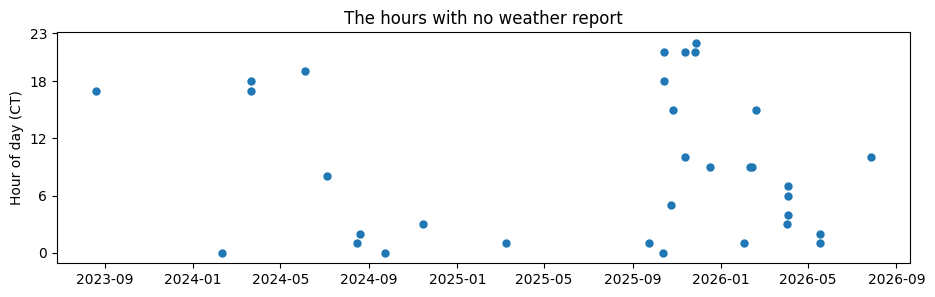

In [10]:
empty = hourly.loc[grid, "weather_imputed"]
empty_local = empty[empty].index.tz_convert("America/New_York")

# How long is each gap? Consecutive empty hours belong to the same gap.
gap_id = (empty != empty.shift()).cumsum()
gap_lengths = empty[empty].groupby(gap_id[empty]).size()
print("Empty hours:", len(empty_local), "| gaps:", len(gap_lengths), "| longest gap:", gap_lengths.max(), "hours")
print("Gap lengths (hours: how many gaps):", gap_lengths.value_counts().sort_index().to_dict())

plt.figure(figsize=(11, 3))
plt.scatter(empty_local, empty_local.hour, s=25)
plt.yticks([0, 6, 12, 18, 23])
plt.ylabel("Hour of day (CT)")
plt.title("The hours with no weather report")
plt.show()

## 4. Tidy the values (and match the forecast's units)
In production, the model gets its weather from our hourly **forecast** scraper, which reads forecast.weather.gov.
The history has to speak the same language as the forecast, or the model learns one thing and is fed another.

**Is sky cover in both? Yes, but in different shapes.**
| | Airport report (METAR): the history | forecast.weather.gov: production |
|---|---|---|
| Sky | Up to **4 cloud layers**, each a code plus a height: FEW (1–2 eighths of the sky covered), SCT (3–4 eighths), BKN (5–7 eighths), OVC (all 8), VV (sky hidden by fog) | **One number**, "Sky Cover (%)", 0 to 100, for every hour |
| Wind | knots | mph |
| Rain | inches in the last hour, "T" for a trace | chance of rain (%) |

So we turn each cloud code into the percent in the **middle** of its range (FEW = 19%, SCT = 44%, BKN = 75%,
OVC = 100%) and keep the **thickest** layer, because the forecast's number is the total cover. Wind goes from knots to
mph. Rain is the one mismatch: the history measures **inches**, the forecast gives a **chance**, which is why rain is
not one of Lab 5's 11 features.

In [11]:
# Rain: "T" (trace) becomes a tiny amount, not zero, so "it drizzled" is still visible
hourly["precip_in"] = pd.to_numeric(hourly["p01i"].replace("T", "0.001"), errors="coerce")

# Wind: knots -> mph (1 knot = 1.15078 mph); no gust reported means gust = the wind speed
KNOTS_TO_MPH = 1.15078
hourly["wind_speed_mph"] = hourly["sknt"] * KNOTS_TO_MPH
hourly["wind_gust_mph"] = hourly["gust"].fillna(hourly["sknt"]) * KNOTS_TO_MPH

# Sky: cloud code -> percent of sky covered (the code's eighths of sky, at the middle of each range).
# A report can list up to 4 layers; the sky is as covered as its THICKEST layer (matches the forecast's "total" cover).
SKY_PERCENT = {"CLR": 0, "FEW": 19, "SCT": 44, "BKN": 75, "OVC": 100, "VV": 100}
layers = pd.DataFrame(index=hourly.index)
for layer in ["skyc1", "skyc2", "skyc3", "skyc4"]:
    layers[layer] = hourly[layer].str.strip().map(SKY_PERCENT)
hourly["cloud_cover_pct"] = layers.max(axis=1)

# Weather codes -> simple yes/no flags
codes = hourly["wxcodes"].fillna("")
hourly["is_rain"] = codes.str.contains("RA|DZ").astype(float)        # rain or drizzle
hourly["is_snow"] = codes.str.contains("SN|PL|GR|GS").astype(float)  # snow, sleet, hail
hourly["is_fog"] = codes.str.contains("FG|BR").astype(float)         # fog or mist

RENAME = {"tmpf": "temp_f", "dwpf": "dewpoint_f", "relh": "rel_humidity_pct", "feel": "feels_like_f",
          "drct": "wind_dir_deg", "alti": "pressure_inhg", "vsby": "visibility_mi"}
weather = hourly.rename(columns=RENAME)
COLUMNS = ["temp_f", "dewpoint_f", "rel_humidity_pct", "feels_like_f", "wind_speed_mph", "wind_gust_mph",
           "wind_dir_deg", "pressure_inhg", "visibility_mi", "cloud_cover_pct", "precip_in",
           "is_rain", "is_snow", "is_fog", "weather_imputed"]
weather = weather[COLUMNS]

# The summary, with a completeness column: what share of the 33,215 hours has a value (before filling)
summary = weather.loc[grid].describe().T[["count", "min", "mean", "max"]].round(1)
summary["complete_pct"] = (100 * summary["count"] / len(grid)).round(2)
summary

,count,min,mean,max,complete_pct
temp_f,33182.0,-9.0,53.6,99.0,99.90
dewpoint_f,33182.0,-29.0,41.3,78.0,99.90
rel_humidity_pct,33182.0,9.6,66.3,100.0,99.90
feels_like_f,33181.0,-31.8,51.5,108.5,99.90
wind_speed_mph,33166.0,0.0,7.4,34.5,99.85
wind_gust_mph,33166.0,0.0,8.7,54.1,99.85
wind_dir_deg,32308.0,0.0,185.1,360.0,97.27
pressure_inhg,33182.0,28.9,30.0,31.0,99.90
visibility_mi,33181.0,0.1,9.2,10.0,99.90
cloud_cover_pct,33182.0,0.0,61.4,100.0,99.90


**Before and after.** A few real hours with more than one cloud layer: the codes on the left, the one percent the
model sees on the right. Same for wind, knots to mph.

In [12]:
examples = hourly.loc[grid].dropna(subset=["skyc2"])
examples = examples[["skyc1", "skyc2", "skyc3", "skyc4", "cloud_cover_pct", "sknt", "wind_speed_mph"]].head(6).copy()
examples.index = examples.index.tz_convert("America/New_York").strftime("%b %d %I %p")
examples["wind_speed_mph"] = examples["wind_speed_mph"].round(1)
examples

,skyc1,skyc2,skyc3,skyc4,cloud_cover_pct,sknt,wind_speed_mph
Jan 01 12 AM,SCT,SCT,OVC,NaN,100.0,8.0,9.2
Jan 01 01 AM,SCT,SCT,OVC,NaN,100.0,7.0,8.1
Jan 01 02 AM,BKN,BKN,OVC,NaN,100.0,7.0,8.1
Jan 01 03 AM,SCT,BKN,BKN,NaN,75.0,0.0,0.0
Jan 01 04 AM,SCT,SCT,NaN,NaN,44.0,3.0,3.5
Jan 01 05 AM,SCT,SCT,SCT,NaN,44.0,3.0,3.5


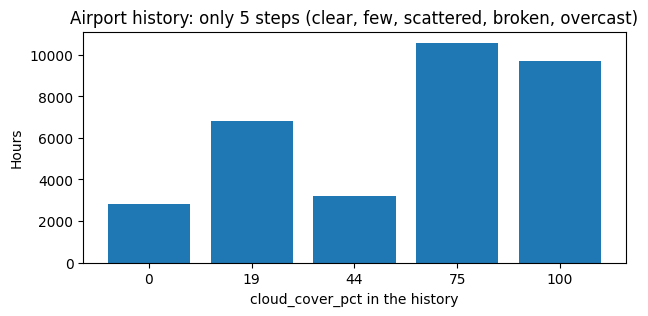

In [13]:
# The history only ever has 5 sky values; the forecast can say anything from 0 to 100
sky_counts = weather.loc[grid, "cloud_cover_pct"].value_counts().sort_index()
plt.figure(figsize=(7, 3))
plt.bar(sky_counts.index.astype(int).astype(str), sky_counts.values)
plt.xlabel("cloud_cover_pct in the history")
plt.ylabel("Hours")
plt.title("Airport history: only 5 steps (clear, few, scattered, broken, overcast)")
plt.show()

**Why that matters:** the model trains on 5 steps but is fed smooth forecast values like 37% or 62% in production.
Trees handle that fine (37% just falls between two steps), but it's one honest reason live error comes in higher than
test error. The same goes for every column: the airport measured it, the forecast predicts it.

**Sanity check the ranges:** −9 °F to 99 °F, humidity about 10–100 %, wind under ~35 mph, visibility 0–10 miles. All
physically sensible for Connecticut, so there are no bad sensor values to remove. (If you ever see 150 °F or −80 °F,
that's a broken sensor: set it to missing and fill it like a gap.)

## 5. Fill the gaps, one variable at a time
Bradley is a well-run airport: only a few dozen empty hours, and no gap longer than 2 hours, so here the choice barely
changes the file. It matters a lot more for a second station, an older year, or your own scraper missing a few runs.
So let's do it properly: **pick each method with evidence**, not habit.

**The defaults baked into the official CSV:**
| Variable | Default | Why |
|---|---|---|
| `temp_f`, `dewpoint_f`, `rel_humidity_pct`, `feels_like_f`, `pressure_inhg`, `visibility_mi` | straight line in time, gaps up to 6 hours | they change smoothly |
| `wind_speed_mph`, `wind_gust_mph`, `cloud_cover_pct` | straight line in time, gaps up to 6 hours | simple, and nothing beats it by much (5c and 5d) |
| `wind_dir_deg` | carry the last value forward, up to 6 hours | it's an angle: a straight line between 350° and 10° goes through 180° (5e) |
| `is_rain`, `is_snow`, `is_fog` | carry forward, up to 6 hours | yes/no values: no "half raining" |
| `precip_in` | 0 | most hours have no rain |
| every filled hour | `weather_imputed = 1` | so you (or a model) can tell real readings from filled ones |

### 5a. The experiment: hide real hours, fill them back, score each method
Take a stretch where every hour is real, **hide** a few hours, fill them with each method, and measure how far off the
fill is from the truth. Repeat at 200 random spots. The method with the smallest average miss wins. Six contenders:
- **carry forward:** repeat the last real value
- **nearest:** copy whichever real value is closer in time
- **straight line:** connect the two real values on either side (`interpolate(method="time")`)
- **smooth curve (pchip):** a curve through the nearby points that bends but never overshoots
- **same hour yesterday:** copy the value from 24 hours earlier
- **yesterday's shape, nudged:** yesterday's ups and downs, shifted so they meet the real values at both ends of the gap

In [14]:
METHODS = ["carry forward", "nearest", "straight line", "smooth curve (pchip)", "same hour yesterday",
           "yesterday's shape, nudged"]


def fill_gap(series, method):
    """Fill the blanks in one stretch of hours with one method."""
    if method == "carry forward":
        return series.ffill()
    elif method == "nearest":
        return series.interpolate(method="nearest")
    elif method == "straight line":
        return series.interpolate(method="time")
    elif method == "smooth curve (pchip)":
        return series.interpolate(method="pchip")
    elif method == "same hour yesterday":
        return series.fillna(series.shift(24))
    elif method == "yesterday's shape, nudged":
        yesterday = series.shift(24)
        difference = (series - yesterday).interpolate(method="time")   # how far today runs above yesterday
        return series.fillna(yesterday + difference)
    else:
        raise ValueError("unknown method: " + method)


def hide_and_score(series, gap_hours, spots=200, seed=42):
    """Hide gap_hours real hours at random spots, fill them with every method, return each method's average miss."""
    rng = np.random.default_rng(seed)
    series = series.loc[grid]
    misses = {}
    for method in METHODS:
        misses[method] = []
    starts = rng.choice(np.arange(48, len(series) - 48 - gap_hours), size=spots, replace=False)
    for start in starts:
        window = series.iloc[start - 48:start + gap_hours + 48].copy()    # 2 days of real hours on each side
        if window.isna().any():
            continue                                                       # skip spots that already have a gap
        truth = window.iloc[48:48 + gap_hours].copy()
        window.iloc[48:48 + gap_hours] = np.nan                            # hide them
        for method in METHODS:
            filled = fill_gap(window, method).iloc[48:48 + gap_hours]
            misses[method].append(np.abs(filled.values - truth.values).mean())
    average = {}
    for method in METHODS:
        average[method] = np.mean(misses[method])
    return pd.Series(average)


def compare_methods(series, gaps, unit):
    """Score every method at every gap length, plot it, and return the table."""
    table = {}
    for gap_hours in gaps:
        table[gap_hours] = hide_and_score(series, gap_hours)
    table = pd.DataFrame(table).T.round(2)
    table.index.name = "gap (hours)"
    plt.figure(figsize=(8, 3.5))
    for method in METHODS:
        plt.plot(table.index, table[method], marker="o", label=method)
    plt.xticks(gaps)
    plt.xlabel("Length of the hidden gap (hours)")
    plt.ylabel("Average miss (" + unit + ")")
    plt.title(series.name + ": lower is better")
    plt.legend(fontsize=8)
    plt.show()
    return table


def show_one_gap(series, first_hidden_local, gap_hours, unit):
    """Hide one real gap and draw every method's fill against the truth."""
    first = pd.Timestamp(first_hidden_local, tz="America/New_York").tz_convert("UTC")
    hidden = pd.date_range(first, periods=gap_hours, freq="h")
    window = series.loc[first - pd.Timedelta(hours=48):hidden[-1] + pd.Timedelta(hours=48)].copy()
    truth = window.loc[hidden].copy()
    window.loc[hidden] = np.nan
    shown = window.loc[first - pd.Timedelta(hours=12):hidden[-1] + pd.Timedelta(hours=12)]
    plt.figure(figsize=(10, 3.5))
    plt.plot(shown.index, shown.values, color="black", marker=".", label="real hours we kept")
    plt.plot(truth.index, truth.values, color="black", linestyle=":", marker="x", label="the hidden truth")
    for method in METHODS:
        plt.plot(hidden, fill_gap(window, method).loc[hidden].values, label=method)
    plt.ylabel(series.name + " (" + unit + ")")
    plt.title("One hidden " + str(gap_hours) + "-hour gap in " + series.name)
    plt.legend(fontsize=8, ncol=2)
    plt.show()

### 5b. Temperature: smooth, and it repeats every day
First one gap you can see: hide 12 hours of a summer day (6 a.m. to 6 p.m.) and watch each method guess.

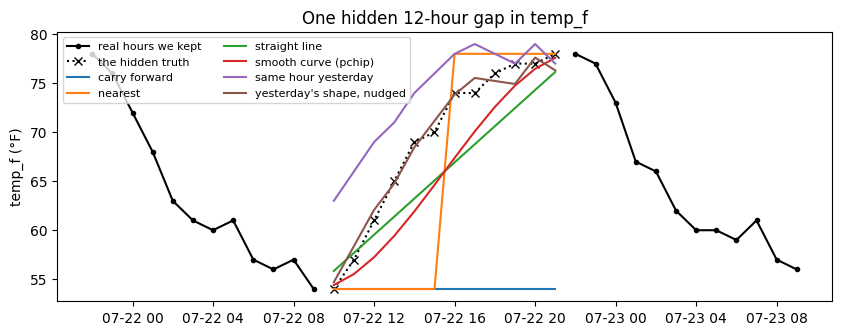

In [15]:
show_one_gap(weather["temp_f"], "2025-07-22 06:00", 12, "°F")

Now the real test: 200 random spots for each gap length. (About 20 seconds.)

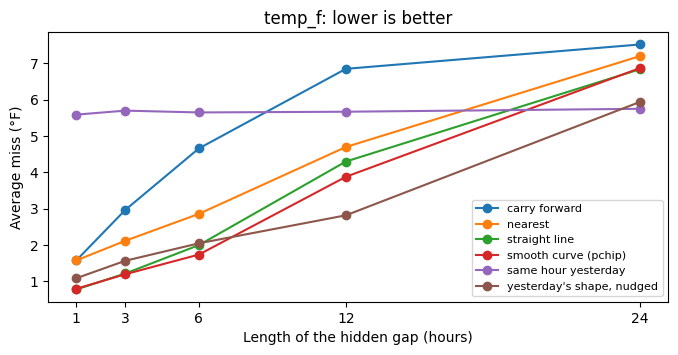

,carry forward,nearest,straight line,smooth curve (pchip),same hour yesterday,"yesterday's shape, nudged"
gap (hours),,,,,,
1,1.58,1.58,0.78,0.80,5.59,1.09
3,2.97,2.12,1.22,1.20,5.70,1.57
6,4.66,2.86,2.00,1.74,5.65,2.05
12,6.85,4.70,4.30,3.88,5.67,2.82
24,7.52,7.20,6.84,6.87,5.75,5.94


In [16]:
temp_table = compare_methods(weather["temp_f"], [1, 3, 6, 12, 24], "°F")
temp_table

**Read it:**
- **Up to 6 hours:** the **straight line** and the **smooth curve** win, both under 2 °F off: temperature doesn't
  change much in a few hours.
- **12 hours:** a straight line cuts right through the afternoon peak (about 4 °F off), while **yesterday's shape,
  nudged** knows days warm up and cool down (under 3 °F off).
- **A whole day:** plain **same hour yesterday** is best: with no real hours nearby, yesterday is all you have.
- **Carry forward** is the worst at every length.

That's why the official file uses a straight line but **only for gaps up to 6 hours**. For a longer outage,
yesterday's shape is the better tool.

### 5c. Wind speed: noisy, and yesterday doesn't help much
Wind jumps around hour to hour and doesn't repeat day to day the way temperature does.

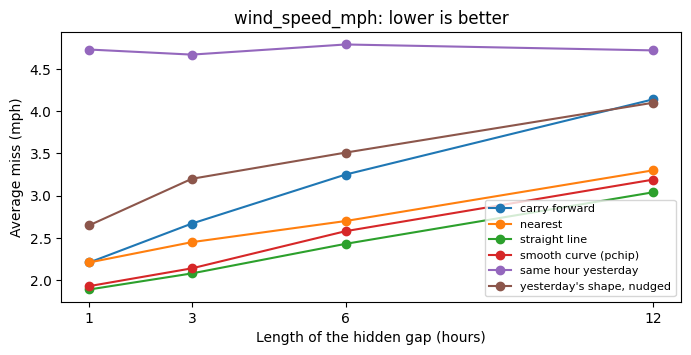

,carry forward,nearest,straight line,smooth curve (pchip),same hour yesterday,"yesterday's shape, nudged"
gap (hours),,,,,,
1,2.21,2.21,1.89,1.93,4.73,2.65
3,2.67,2.45,2.08,2.14,4.67,3.20
6,3.25,2.70,2.43,2.58,4.79,3.51
12,4.14,3.30,3.04,3.19,4.72,4.10


In [17]:
wind_table = compare_methods(weather["wind_speed_mph"], [1, 3, 6, 12], "mph")
wind_table

**Read it:** every method misses by a few mph, because wind is noisy. Copying yesterday is clearly worse here: windy
days don't come in daily cycles the way warm afternoons do. A straight line is about as good as anything, so it's the
default.

### 5d. Cloud cover: it jumps between 5 steps
The history only has 0, 19, 44, 75 and 100%. A straight line fills in values like 60% that the airport never
reports. Is that a problem?

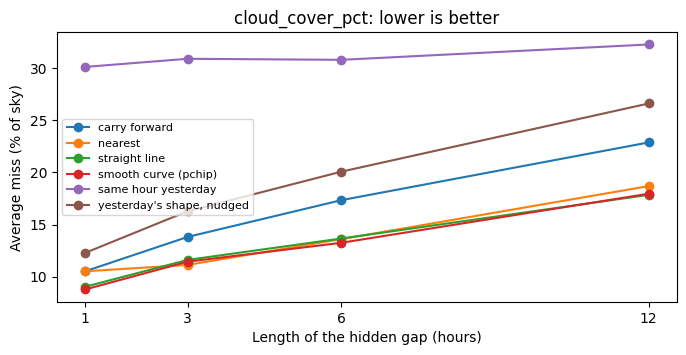

,carry forward,nearest,straight line,smooth curve (pchip),same hour yesterday,"yesterday's shape, nudged"
gap (hours),,,,,,
1,10.53,10.53,9.05,8.79,30.10,12.29
3,13.82,11.14,11.62,11.45,30.88,16.28
6,17.34,13.61,13.67,13.26,30.78,20.07
12,22.87,18.69,17.85,17.96,32.25,26.60


In [18]:
cloud_table = compare_methods(weather["cloud_cover_pct"], [1, 3, 6, 12], "% of sky")
cloud_table

**Read it:** **nearest**, **straight line** and **smooth curve** are close. Carry forward and yesterday are worse:
clouds come and go. In-between values like 60% are fine, because the live forecast gives in-between values too
(Part 4). Straight line is the default.

### 5e. Wind direction: it's an angle
North is both 0° and 360°. A straight line from **350°** (just west of north) to **10°** (just east of north) passes
through **180°**, which is due south. Wrong by half a circle.

In [19]:
directions = pd.Series([350.0, np.nan, 10.0])
print("Straight line between 350° and 10°:", directions.interpolate().iloc[1], "degrees  <- south, wrong")

# The fix: split the angle into an east part and a north part, fill those, and turn them back into an angle
radians = np.deg2rad(directions)
east = np.sin(radians).interpolate()
north = np.cos(radians).interpolate()
print("Through the east and north parts:", round(np.rad2deg(np.arctan2(east.iloc[1], north.iloc[1]))) % 360, "degrees  <- north, right")

Straight line between 350° and 10°: 180.0 degrees  <- south, wrong
Through the east and north parts: 0 degrees  <- north, right


The official file keeps it simple and **carries the last direction forward** (up to 6 hours). If you use wind
direction as a model feature, the same idea helps the model: give it `sin` and `cos` of the angle instead of the raw
degrees, so 359° and 1° look like neighbors.

### 5f. Rain and the yes/no flags
- `precip_in`: a missing hour becomes **0**. Most hours are dry, and a gap is usually a quiet hour, not a storm.
- `is_rain`, `is_snow`, `is_fog`: **carry forward** up to 6 hours. They're 0 or 1, and a straight line would invent
  "half raining".

### 5g. Apply the defaults
This is the cell that built the official CSV. Leave it as is to match the GitHub file in Part 7.

In [20]:
NUMBERS = ["temp_f", "dewpoint_f", "rel_humidity_pct", "feels_like_f", "wind_speed_mph", "wind_gust_mph",
           "pressure_inhg", "visibility_mi", "cloud_cover_pct"]
FLAGS = ["is_rain", "is_snow", "is_fog"]

weather[NUMBERS] = weather[NUMBERS].interpolate(method="time", limit=6, limit_direction="both")
weather["wind_dir_deg"] = weather["wind_dir_deg"].ffill(limit=6)
weather[FLAGS] = weather[FLAGS].ffill(limit=6)
weather["precip_in"] = weather["precip_in"].fillna(0.0)

weather = weather.loc[grid]                                     # drop the padding

# Squeaky clean: sensible decimals, and yes/no flags as 0/1 integers
ROUNDING = {"temp_f": 1, "dewpoint_f": 1, "rel_humidity_pct": 1, "feels_like_f": 1, "wind_speed_mph": 1,
            "wind_gust_mph": 1, "wind_dir_deg": 0, "pressure_inhg": 2, "visibility_mi": 2, "cloud_cover_pct": 0,
            "precip_in": 3}
for column in ROUNDING:
    weather[column] = weather[column].round(ROUNDING[column])
for column in FLAGS:
    weather[column] = weather[column].astype(int)
weather["weather_imputed"] = weather["weather_imputed"].astype(int)
print("Rows:", len(weather))
print("Missing values left:", int(weather.isna().sum().sum()))
print("Filled (imputed) hours:", int(weather["weather_imputed"].sum()))

Rows: 33215
Missing values left: 0
Filled (imputed) hours: 33


**Your turn (optional):** swap in a better method for long gaps, for example:
```python
weather["temp_f"] = fill_gap(weather["temp_f"], "yesterday's shape, nudged")
```
**One rule if you do:** be **consistent**. Whatever you choose, use the exact same rounding, units, fill methods and
limits for **every station** and every year, and make your live `forecast-24h` treat its weather the same way. A model
trained on data cleaned one way and fed data cleaned another way gets quietly worse. (Your copy also won't match the
official file in Part 7 anymore, and that's fine for your own project.)

## 6. The Connecticut load
We pulled ISO New England's **real-time hourly demand** for the Connecticut zone (location 4004), one day at a time,
through ISO Express web services (you'll get your own free account for the hourly scraper). Each row has the hour's
start time **with its UTC offset**: `-05:00` in winter (EST) and `-04:00` in summer (EDT). That offset is what makes the
daylight-saving hours unambiguous.

**Good news first:** the load is complete. Every hour is there and nothing is missing, so there is nothing to fill.
The only work is getting the clock right.

In [21]:
load_raw = pd.read_csv(DATA + "raw/ct_hourly_load_2023_2026_raw.csv")
print(len(load_raw), "rows")
load_raw.head()

33215 rows


,begin_date,location,loc_id,load_mw
0,2023-01-01T00:00:00.000-05:00,.Z.CONNECTICUT,4004,2402.708
1,2023-01-01T01:00:00.000-05:00,.Z.CONNECTICUT,4004,2296.444
2,2023-01-01T02:00:00.000-05:00,.Z.CONNECTICUT,4004,2206.413
3,2023-01-01T03:00:00.000-05:00,.Z.CONNECTICUT,4004,2165.396
4,2023-01-01T04:00:00.000-05:00,.Z.CONNECTICUT,4004,2153.655


Rows: 33215 | missing load values: 0 | zero or negative: 0


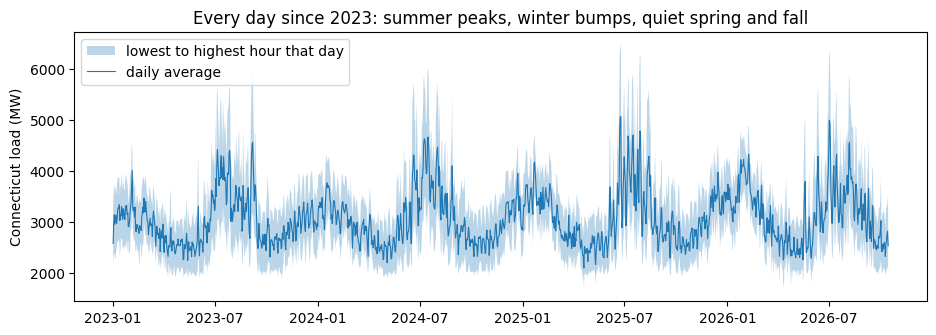

In [22]:
# Completeness and sanity: no blanks, nothing zero or negative, and a look at the whole history
print("Rows:", len(load_raw), "| missing load values:", int(load_raw["load_mw"].isna().sum()),
      "| zero or negative:", int((load_raw["load_mw"] <= 0).sum()))

daily = load_raw.copy()
daily["hour_utc"] = pd.to_datetime(daily["begin_date"], utc=True)
daily = daily.set_index("hour_utc")["load_mw"].tz_convert("America/New_York").resample("D").agg(["min", "mean", "max"])
plt.figure(figsize=(11, 3.5))
plt.fill_between(daily.index, daily["min"], daily["max"], alpha=0.3, label="lowest to highest hour that day")
plt.plot(daily.index, daily["mean"], linewidth=0.8, label="daily average")
plt.ylabel("Connecticut load (MW)")
plt.title("Every day since 2023: summer peaks, winter bumps, quiet spring and fall")
plt.legend()
plt.show()

### 6a. The daylight-saving trap, before and after

In [23]:
# Parse each local time with its own offset, then convert to UTC
load = load_raw.copy()
load["hour_utc"] = pd.to_datetime(load["begin_date"], utc=True)

# Look at the two daylight-saving days of 2024
load["local_day"] = pd.to_datetime(load["begin_date"].str.slice(0, 10))
hours_per_day = load.groupby("local_day").size()
print("Hours in a normal local day:", hours_per_day.mode()[0])
print("Days that aren't 24 hours (daylight saving):")
print(hours_per_day[hours_per_day != 24])

Hours in a normal local day: 24
Days that aren't 24 hours (daylight saving):
local_day
2023-03-12    23
2023-11-05    25
2024-03-10    23
2024-11-03    25
2025-03-09    23
2025-11-02    25
2026-03-08    23
dtype: int64


March days have **23** hours (2 a.m. never happens) and November days have **25** (1 a.m. happens twice). Here's the
fall-back night of 2024, row by row. Look at the clock column: **1:00 shows up twice**. Only the offset tells the two
apart, and in UTC they're simply two different hours.

In [24]:
fall_back = load_raw[load_raw["begin_date"].str.startswith("2024-11-03")].head(4).copy()
fall_back["local clock"] = fall_back["begin_date"].str.slice(11, 16)
fall_back["offset"] = fall_back["begin_date"].str.slice(-6)
fall_back["UTC"] = pd.to_datetime(fall_back["begin_date"], utc=True).dt.strftime("%b %d %H:%M")
fall_back[["begin_date", "local clock", "offset", "UTC", "load_mw"]]

,begin_date,local clock,offset,UTC,load_mw
16127,2024-11-03T00:00:00.000-04:00,00:00,-04:00,Nov 03 04:00,2212.623
16128,2024-11-03T01:00:00.000-04:00,01:00,-04:00,Nov 03 05:00,2130.786
16129,2024-11-03T01:00:00.000-05:00,01:00,-05:00,Nov 03 06:00,2082.032
16130,2024-11-03T02:00:00.000-05:00,02:00,-05:00,Nov 03 07:00,2064.293


And the spring-forward night of 2024: the clock jumps from 1:00 to 3:00. In UTC there's no hole at all.

In [25]:
spring = load_raw[load_raw["begin_date"].str.startswith("2024-03-10")].head(4).copy()
spring["local clock"] = spring["begin_date"].str.slice(11, 16)
spring["offset"] = spring["begin_date"].str.slice(-6)
spring["UTC"] = pd.to_datetime(spring["begin_date"], utc=True).dt.strftime("%b %d %H:%M")
spring[["begin_date", "local clock", "offset", "UTC", "load_mw"]]

,begin_date,local clock,offset,UTC,load_mw
10416,2024-03-10T00:00:00.000-05:00,00:00,-05:00,Mar 10 05:00,2542.784
10417,2024-03-10T01:00:00.000-05:00,01:00,-05:00,Mar 10 06:00,2440.024
10418,2024-03-10T03:00:00.000-04:00,03:00,-04:00,Mar 10 07:00,2369.346
10419,2024-03-10T04:00:00.000-04:00,04:00,-04:00,Mar 10 08:00,2351.325


**What goes wrong if you ignore the offset?** Read the times as plain local clock times (drop the `-05:00`), and
count the damage over the whole file:

In [26]:
local_clock = pd.to_datetime(load_raw["begin_date"].str.slice(0, 19))      # offset dropped: the mistake
every_local_hour = pd.date_range(local_clock.min(), local_clock.max(), freq="h")
print("Local clock: duplicate times:", int(local_clock.duplicated().sum()),
      "| clock hours with no row:", len(every_local_hour.difference(local_clock)))

utc_time = pd.to_datetime(load_raw["begin_date"], utc=True)                # offset kept: the fix
every_utc_hour = pd.date_range(utc_time.min(), utc_time.max(), freq="h")
print("UTC:         duplicate times:", int(utc_time.duplicated().sum()),
      "| hours with no row:", len(every_utc_hour.difference(utc_time)))

Local clock: duplicate times: 3 | clock hours with no row: 4
UTC:         duplicate times: 0 | hours with no row: 0


On local clock time, the 3 fall-back hours would each match **two** weather rows in a join (the wrong weather for
one of them), and the 4 spring-forward hours look like holes that a careless fill would invent load for. In UTC:
zero duplicates, zero holes. Here's the same thing as a picture:

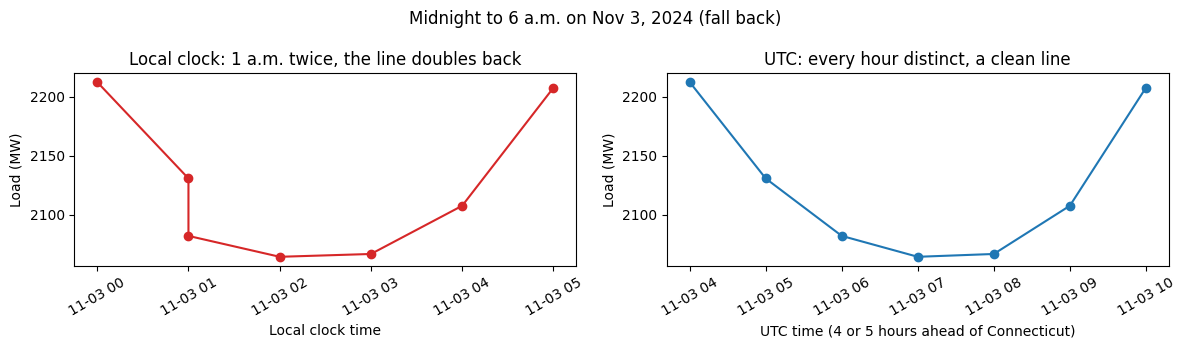

In [27]:
night = load_raw[load_raw["begin_date"].str.startswith("2024-11-03")].head(7)
night_clock = pd.to_datetime(night["begin_date"].str.slice(0, 19))
night_utc = pd.to_datetime(night["begin_date"], utc=True).dt.tz_convert(None)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(night_clock, night["load_mw"], marker="o", color="tab:red")
ax[0].set_title("Local clock: 1 a.m. twice, the line doubles back")
ax[1].plot(night_utc, night["load_mw"], marker="o")
ax[1].set_title("UTC: every hour distinct, a clean line")
ax[0].set_xlabel("Local clock time")
ax[1].set_xlabel("UTC time (4 or 5 hours ahead of Connecticut)")
for axis in ax:
    axis.set_ylabel("Load (MW)")
    axis.tick_params(axis="x", rotation=30)
plt.suptitle("Midnight to 6 a.m. on Nov 3, 2024 (fall back)")
plt.tight_layout()
plt.show()

In [28]:
load = load.drop_duplicates("hour_utc").set_index("hour_utc").sort_index()
load = load.reindex(grid)
print("Load hours:", len(load), "| missing:", int(load["load_mw"].isna().sum()))

Load hours: 33215 | missing: 0


## 7. Join, check, save
Weather and load both live on the same UTC grid now, so the join is one line, and the checks prove the golden rule.

In [29]:
df = weather.join(load[["load_mw"]], how="left")
df.index.name = "hour_utc"

# Local time, for humans (and for features like "hour of the day" later)
df["hour_local"] = df.index.tz_convert("America/New_York").strftime("%Y-%m-%d %H:%M %Z")

# The golden rule checks
assert len(df) == 33215, "rows must equal hours"
assert df.index.is_unique, "no duplicate hours"
assert df.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all(), "no gaps"
assert df["load_mw"].notna().all(), "every hour has load"
assert df[NUMBERS].notna().all().all(), "every hour has weather"
print("All checks passed:", len(df), "rows, one per hour, no gaps, no duplicates, nothing missing.")
df.head()

All checks passed: 33215 rows, one per hour, no gaps, no duplicates, nothing missing.


,temp_f,dewpoint_f,rel_humidity_pct,feels_like_f,wind_speed_mph,wind_gust_mph,wind_dir_deg,pressure_inhg,visibility_mi,cloud_cover_pct,precip_in,is_rain,is_snow,is_fog,weather_imputed,load_mw,hour_local
hour_utc,,,,,,,,,,,,,,,,,
2023-01-01 05:00:00+00:00,50.0,48.0,92.8,50.0,9.2,9.2,180.0,29.70,0.25,100.0,0.04,1,0,1,0,2402.708,2023-01-01 00:00 EST
2023-01-01 06:00:00+00:00,50.0,49.0,96.0,50.0,8.1,8.1,170.0,29.69,3.00,100.0,0.02,1,0,1,0,2296.444,2023-01-01 01:00 EST
2023-01-01 07:00:00+00:00,50.0,49.0,96.0,50.0,8.1,8.1,220.0,29.68,0.75,100.0,0.01,0,0,1,0,2206.413,2023-01-01 02:00 EST
2023-01-01 08:00:00+00:00,48.0,48.0,100.0,48.0,0.0,0.0,0.0,29.68,3.00,75.0,0.00,0,0,1,0,2165.396,2023-01-01 03:00 EST
2023-01-01 09:00:00+00:00,48.0,46.0,92.7,47.0,3.5,3.5,210.0,29.69,1.00,44.0,0.00,0,0,1,0,2153.655,2023-01-01 04:00 EST


In [30]:
df.to_csv("bdl_ct_load_hourly_2023_2026.csv")
print("Saved bdl_ct_load_hourly_2023_2026.csv")

Saved bdl_ct_load_hourly_2023_2026.csv


### Does yours match the official file?
The official copy, the one Lab 5, Lab 6 and the final project read, is always on GitHub at
[`Module4/data/bdl_ct_load_hourly_2023_2026.csv`](https://github.com/drdave-teaching/OPIM5512-notebooks/blob/main/Module4/data/bdl_ct_load_hourly_2023_2026.csv).
If you ran every cell with the defaults, yours is the same, number for number:

In [31]:
official = pd.read_csv(DATA + "bdl_ct_load_hourly_2023_2026.csv", index_col="hour_utc", parse_dates=["hour_utc"])
mine = pd.read_csv("bdl_ct_load_hourly_2023_2026.csv", index_col="hour_utc", parse_dates=["hour_utc"])
numbers = mine.select_dtypes("number").columns
print("Same hours:", mine.index.equals(official.index))
print("Same columns, same order:", list(mine.columns) == list(official.columns))
print("Biggest difference in any number:", (mine[numbers] - official[numbers]).abs().max().max())

Same hours: True
Same columns, same order: True
Biggest difference in any number: 0.0


**Adding more weather stations?** Run this whole notebook once per station with **the same settings**: same rounding
to the hour, same units, same fill methods and limits, same grid. Prefix the columns (`hfd_temp_f`, `bdr_temp_f`)
before joining, and make sure your forecast scraper produces the same columns every hour in production. See
`Module4/data/README.md` for the stations.

## 8. First look: why weather predicts electricity
Connecticut uses the most electricity when it's **hot** (air conditioning) and a lot when it's **cold** (heating and
lighting), and the least on mild spring and fall days. That's a **U-shape**, and it's why temperature is the star
feature for load forecasting.

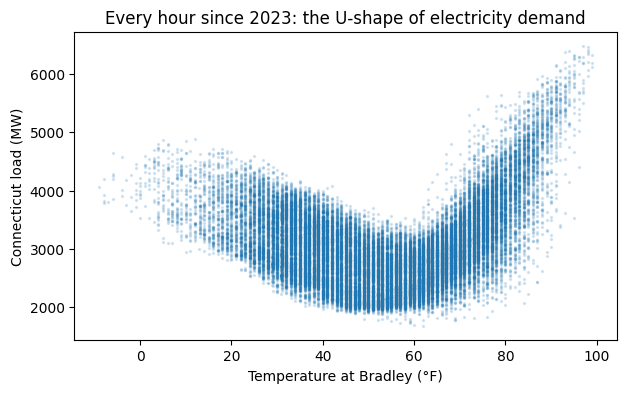

In [32]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df["temp_f"], df["load_mw"], s=2, alpha=0.15)
ax.set_xlabel("Temperature at Bradley (°F)")
ax.set_ylabel("Connecticut load (MW)")
ax.set_title("Every hour since 2023: the U-shape of electricity demand")
plt.show()

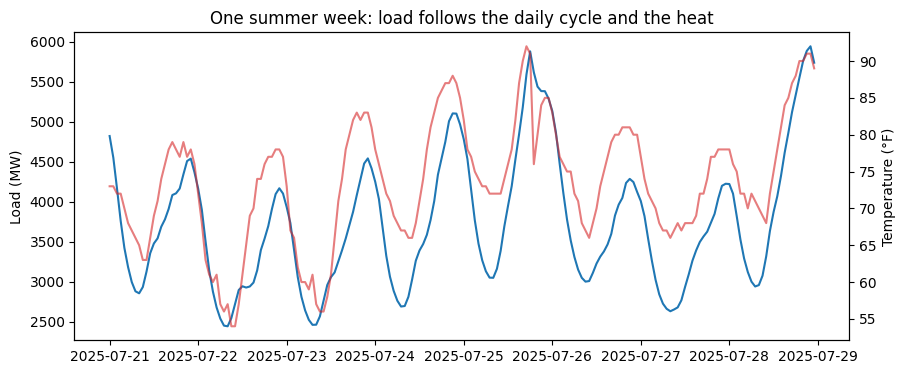

In [33]:
week = df.loc["2025-07-21":"2025-07-28"]
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(week.index, week["load_mw"], label="Connecticut load (MW)")
ax1.set_ylabel("Load (MW)")
ax2 = ax1.twinx()
ax2.plot(week.index, week["temp_f"], color="tab:red", alpha=0.6, label="Temperature (°F)")
ax2.set_ylabel("Temperature (°F)")
ax1.set_title("One summer week: load follows the daily cycle and the heat")
plt.show()

## 9. Preview: the window method (lags)
The **window method** uses the target's own past as features: the load 24 hours ago, 48 hours ago, a week ago, the
average of yesterday. It works because electricity use repeats: today looks a lot like yesterday, and this Tuesday
looks like last Tuesday.

**Why the golden rule pays off here:** `shift(24)` moves a column down 24 **rows**. That's 24 **hours** only because
there are no gaps and no duplicates. On local clock time, the daylight-saving days would make it 23 or 25.

First, how similar is the load to itself some hours back? (Correlation 1 = identical pattern.)

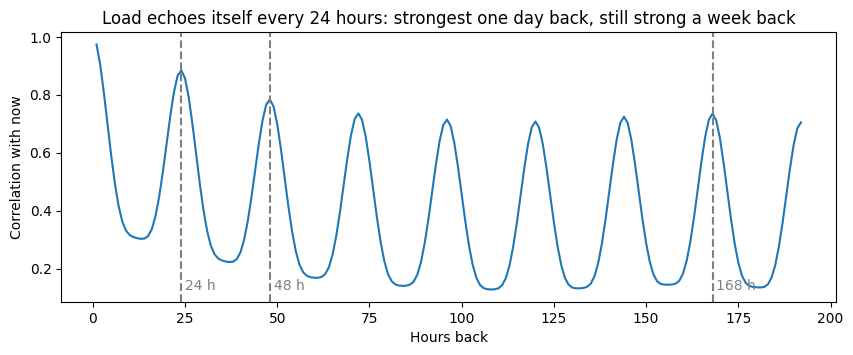

In [34]:
lags = list(range(1, 24 * 8 + 1))              # 1 hour back to 8 days back
correlations = []
for lag in lags:
    correlations.append(df["load_mw"].autocorr(lag))

plt.figure(figsize=(10, 3.5))
plt.plot(lags, correlations)
for mark in [24, 48, 168]:
    plt.axvline(mark, color="gray", linestyle="--")
    plt.text(mark + 1, min(correlations), str(mark) + " h", color="gray")
plt.xlabel("Hours back")
plt.ylabel("Correlation with now")
plt.title("Load echoes itself every 24 hours: strongest one day back, still strong a week back")
plt.show()

Copy-paste lags: each column looks back a fixed number of hours. **The production rule:** `forecast-24h` predicts up to
24 hours ahead with one model, so every **load** lag must be at least 24 hours old (the 1-hour-ago load doesn't exist
yet for tomorrow afternoon). That's why Lab 5 uses `load_yesterday_mw` and nothing newer.

Correlation with load_mw:
load_24h_ago             0.884
load_48h_ago             0.784
load_168h_ago            0.735
load_avg_of_yesterday    0.609
temp_3h_ago              0.186
temp_f                   0.182
Name: load_mw, dtype: float64


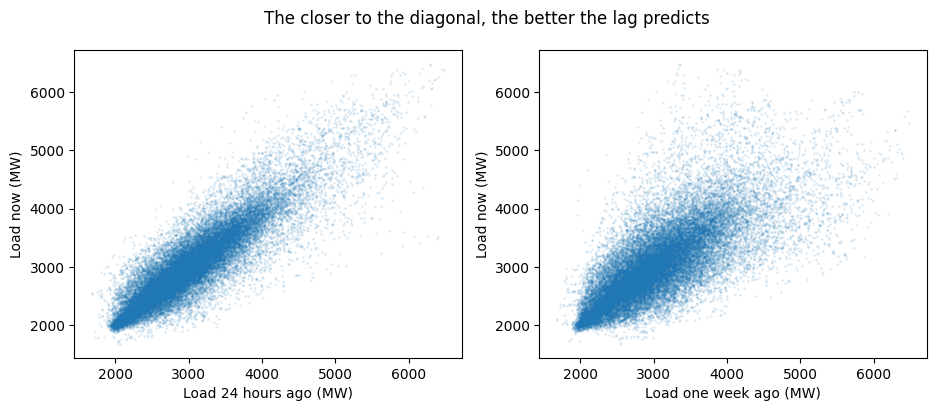

In [35]:
lagged = df[["load_mw", "temp_f"]].copy()
for hours_back in [24, 48, 168]:
    lagged["load_" + str(hours_back) + "h_ago"] = lagged["load_mw"].shift(hours_back)
lagged["load_avg_of_yesterday"] = lagged["load_mw"].shift(24).rolling(24).mean()    # the 24 hours ending 24 h ago
lagged["temp_3h_ago"] = lagged["temp_f"].shift(3)
lagged = lagged.dropna()                       # the first week has no "a week ago"

print("Correlation with load_mw:")
print(lagged.corr()["load_mw"].drop("load_mw").round(3).sort_values(ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(lagged["load_24h_ago"], lagged["load_mw"], s=1, alpha=0.1)
ax[0].set_xlabel("Load 24 hours ago (MW)")
ax[1].scatter(lagged["load_168h_ago"], lagged["load_mw"], s=1, alpha=0.1)
ax[1].set_xlabel("Load one week ago (MW)")
for axis in ax:
    axis.set_ylabel("Load now (MW)")
plt.suptitle("The closer to the diagonal, the better the lag predicts")
plt.show()

The **Lab 5 bonus notebook** (`Lab5_Bonus_Features_Ensembles_Ranges.ipynb`) puts these lags into a model and tests
whether they beat Lab 5's 11 features.

## What you have now
A table you can trust: **33,215 hours**, weather and load side by side, in UTC, nothing missing, every filled value
flagged, and identical to the official file on GitHub. Next in Lab 5: turn the timestamp into features (hour of the
day, day of the week, holidays), add the load 24 hours ago, and fit your first real forecasting model.

**Data credits:** weather from the Iowa State Mesonet (mesonet.agron.iastate.edu) archive of NWS/FAA airport reports;
load from ISO New England (iso-ne.com, ISO Express web services, real-time hourly demand, Connecticut load zone).